# Práctica 2

**Mateo Zariquiey Pérez     100522396**

**Héctor Fuertes Muñoz      100522401**


## 1. Introducción y objetivos

En esta práctica se trate un problema de **aprendizaje no supervisado**, cuyo objetivo es identificar los posibles patrones y agrupaciones presentese un dataset  sin disponer de etiquetas previas. A diferencia de un aprendizaje supervisado, en este caso no se parte de una variable objetivo conocida, sino que se explora la estructura interna de los datos a partir de las relaciones y similitudes que presentan entre sus atributos.

Por lo tanto, en esta práctica se trabajará con un dataset formado por las características de distintas estrellas, que será la base utilizada para aplicar las técnicas de **clustering**. El análisis se dividirá en:
+ Transformaciónd e los datos.
+ Reducción de dimensionalidad (PCA).
+ Aplicación de los distintos algoritmos de clustering.

También se estudiará como la representación de los datos influye en la capacidad de los algoritmos para detectar distinitas agrupaciones.

A lo largo de la práctica se utilizarán varimos métodos de clustering con la finalidad de comaprar sus comportamientos, analizar los resultados y valorar cual es el más adecuado para este caso. 


## 2. Carga del dataset

En esta sección se realiza la carga del dataset para la práctica. Además se establece la configuración inicial del entorno. En nuestro caso se fija la semilla con el NIA: 100522401 tal y como indica en el enunciado de la práctica.


In [1]:
# imports básicos
import numpy as np
import pandas as pd

# Se establece la semilla
SEED = 100522401
np.random.seed(SEED)

# Carga del dataset
df = pd.read_csv('../data/stars_data.csv')

df.head()
print("\nDataset cargado correctamente")


Dataset cargado correctamente


## 3. EDA

En este apartado se realiza un análisis exploratorio de los datos o **EDA**. En problemas de aprendizaje no supervisado, esta dase es crucial ya que la calidad de los resultados obtenidos depende en gran medida de cómo estén representados los datos y de si existen diferencias de escalado, valores atípicos o inconsistencias en las variables categóricas. 

Entonces, esta sección se analizará:
* Estructura general del conjunto de datos
* Valores faltantes y duplicados.
* Análisis de variables numéricas.
* Posibles columnas id.
* Valores atípicos.
* Valores presentes en las variables categóricas.
* Análisis básico de las relaciones entre variables numéricas.

### 3.1 Estructura general del conjunto de datos
A continuación se realiza una primera inspección general del dataset con el objetivo de conocer su estructura básica. Antes de omenzar con un análisis más detallado, es conveniente revisar las variables disponibles, que tipo de dato maneja cada una y el número de observaciones que tienen. 

In [2]:
# DImensión del dataset
print("Dimensión del dataset")
print(df.shape)

# Columnas
print("\nNombre de las columnas:")
print(df.columns.tolist())

# Rows
print("\nPrimeras filas del dataset")
display(df.head())

# Información general del dataset
print("\nInformación general del dataset")
df.info()

# Tipos de datos
print("\nTipos de datos por columna")
display(df.dtypes)

Dimensión del dataset
(240, 6)

Nombre de las columnas:
['Temperature', 'L', 'R', 'A_M', 'Color', 'Spectral_Class']

Primeras filas del dataset


,Temperature,L,R,A_M,Color,Spectral_Class
0,3068,0.002400,0.1700,16.12,Red,M
1,3042,0.000500,0.1542,16.60,Red,M
2,2600,0.000300,0.1020,18.70,Red,M
3,2800,0.000200,0.1600,16.65,Red,M
4,1939,0.000138,0.1030,20.06,Red,M



Información general del dataset
<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Temperature     240 non-null    int64  
 1   L               240 non-null    float64
 2   R               240 non-null    float64
 3   A_M             240 non-null    float64
 4   Color           240 non-null    str    
 5   Spectral_Class  240 non-null    str    
dtypes: float64(3), int64(1), str(2)
memory usage: 11.4 KB

Tipos de datos por columna


Temperature         int64
L                 float64
R                 float64
A_M               float64
Color                 str
Spectral_Class        str
dtype: object

En esta primera inspección, se observa que el dataset está formado por **240 features y 6 variables**. Se aprecia la existencia de **cuatro variables numércias** (`Temperature`, `L`, `R` y `A_M`) y **dos variables categóricas** (`Color` y `Spectral_Class`). Las distintas variables recibirán un trato acorde al tipo de dato que representen.

Además, en este apartado puede comprobarse que todas las columnas tienen **240 valores no nulos**, por lo que, en principio, no se detectan problemas de ausencia de datos en esta primera revisión.

### 3.2 Valores faltantes y duplicados

En este apartado se comprueba si existen **valores faltantes** o **filas duplicadas**, ya que ambos aspectos pueden afectar al comportamiento de los algorimos y a la interpretación de los resultados.


In [3]:
print("Número de valores nulos por columna:")
display(df.isnull().sum())

print("\nNúmero de filas duplicadas:")
print(df.duplicated().sum())

Número de valores nulos por columna:


Temperature       0
L                 0
R                 0
A_M               0
Color             0
Spectral_Class    0
dtype: int64


Número de filas duplicadas:
0


Se observa que el dataset **no presenta valores nulos en ninguna de sus variables** ni tampoco **filas duplicadas**. Esto quiere decir que, al menos en esta fase inicial no existen problemas relacionados con la ausencia de información o con la repetición exacta de los registros.

Consecuentemente, no será necesario aplicar técnicas de imputación ni eliminar observaciones duplicadas antes de continuar con el análisis.

### 3.3 Análisis de variables numéricas

En este apartado se analizan las variables numéricas del dataset con el fin de estudiar su comportamiento general. En particular, se observará el rango de valores y si presentan diferencias importantes de magnitud. 

Variables numéricas del dataset:
['Temperature', 'L', 'R', 'A_M']

Resumen estadístico de las variables numéricas:


,count,mean,std,min,25%,50%,75%,max
Temperature,240.0,10497.462500,9552.425037,1939.00000,3344.250000,5776.0000,15055.5000,40000.00
L,240.0,107188.361635,179432.244940,0.00008,0.000865,0.0705,198050.0000,849420.00
R,240.0,237.157781,517.155763,0.00840,0.102750,0.7625,42.7500,1948.50
A_M,240.0,4.382396,10.532512,-11.92000,-6.232500,8.3130,13.6975,20.06


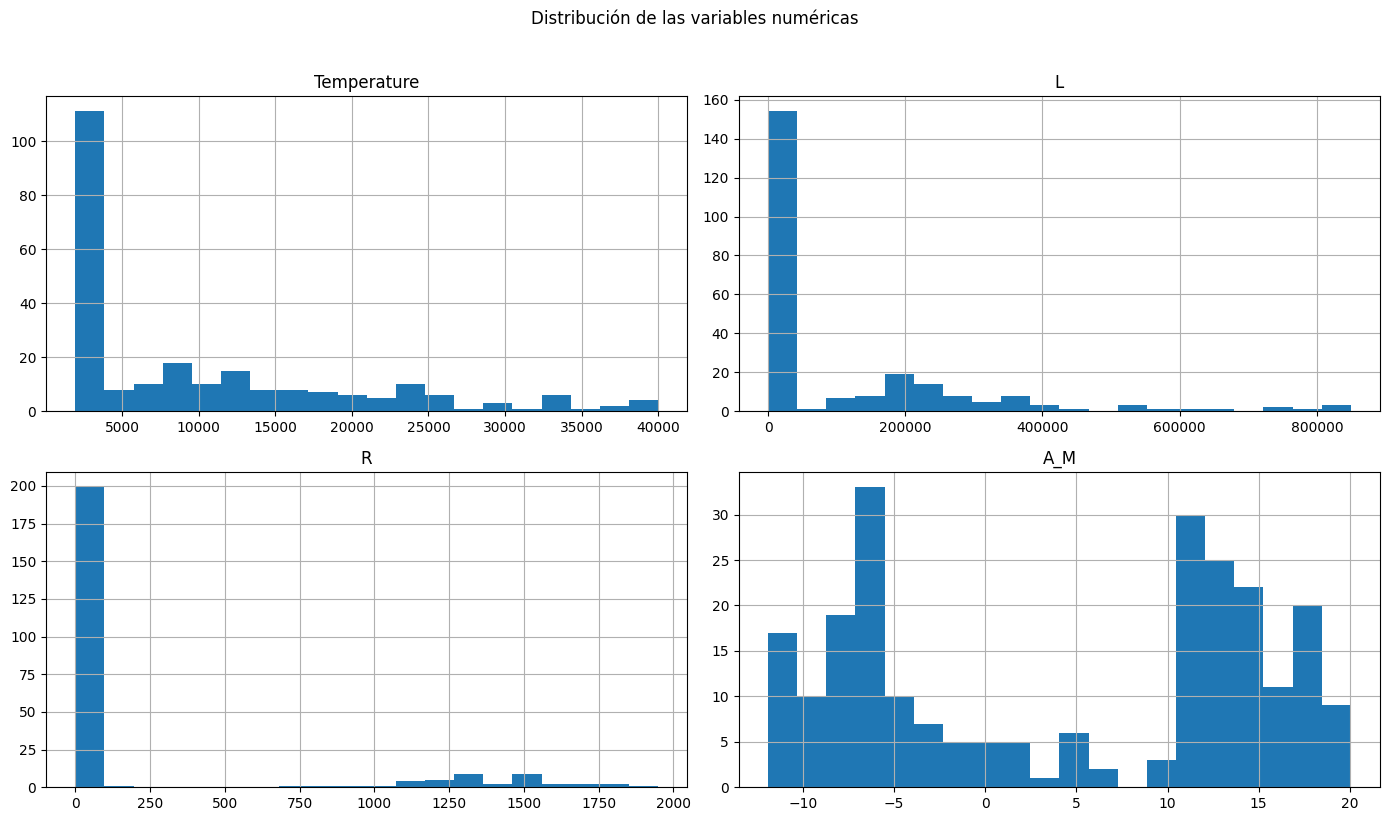

In [4]:
import matplotlib.pyplot as plt

# Selección de variables numéricas
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Variables numéricas del dataset:")
print(num_cols)

print("\nResumen estadístico de las variables numéricas:")
display(df[num_cols].describe().T)

# Histogramas
df[num_cols].hist(figsize=(14, 8), bins=20)
plt.suptitle("Distribución de las variables numéricas", y=1.02)
plt.tight_layout()
plt.show()

## 3.4 Posibles columnas id

En esta sección se revisa si alguna de las variables del dataset puede estar actuando como identificador de las features. Este tipo de columnas no le aportan al modelo información relevante y por lo tanto no se deben incluir como parte del dataset para entrenar el modelo.

In [5]:
print("Número de valores únicos por columna:")
display(df.nunique())

Número de valores únicos por columna:


Temperature       228
L                 208
R                 216
A_M               228
Color              17
Spectral_Class      7
dtype: int64

No se observa ninguna variable que actúe como identificador. Aunque algunas variables numéricas presentan una gran cantidad de valores distintos, esto es de esperar al tratarse de atributos continuos. Por tanto, **no es necesario eliminar nunguna columna** por este motivo.

## 3.5 Valores atípicos

A continuación se estudia la posible presencia de valores atípicos en las varibles numéricas. Detectar estas variables es importante, ya que pueden influir en la representación de los datos y en el comportamiendo de algunos algoritmos de clustering.

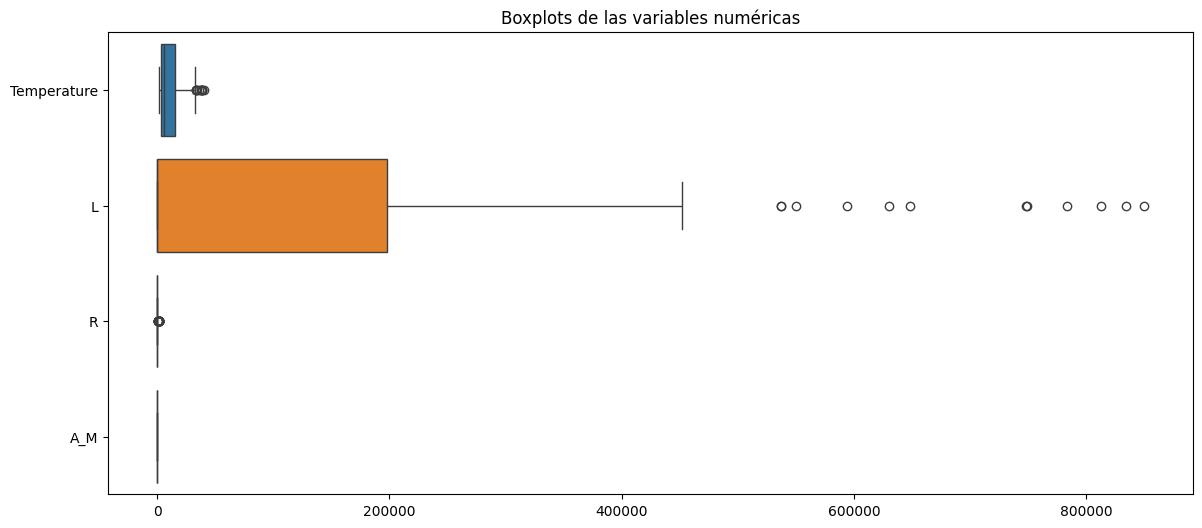

In [7]:
import seaborn as sns

plt.figure(figsize=(14, 6))
sns.boxplot(data=df[num_cols], orient="h")
plt.title("Boxplots de las variables numéricas")
plt.show()

Los boxplots permiten confirmar la presencia de **valores atípicos**, especialmente en la variable `L`, qyue presenta varias features muy alejadas del resto. También se observan puntos extremos en `Temperature`, aunque de forma menos pronunciada. No obstante, diferencia de escala entre las variables dificulta la interpretación. Esto refuerza la idea de que será necesario aplicar **escalado** antes de utilizar técnicas como PCA o clustering.

Ahora, para analizar correctamente las variables se realizará un boxplot por cada una de ellas.

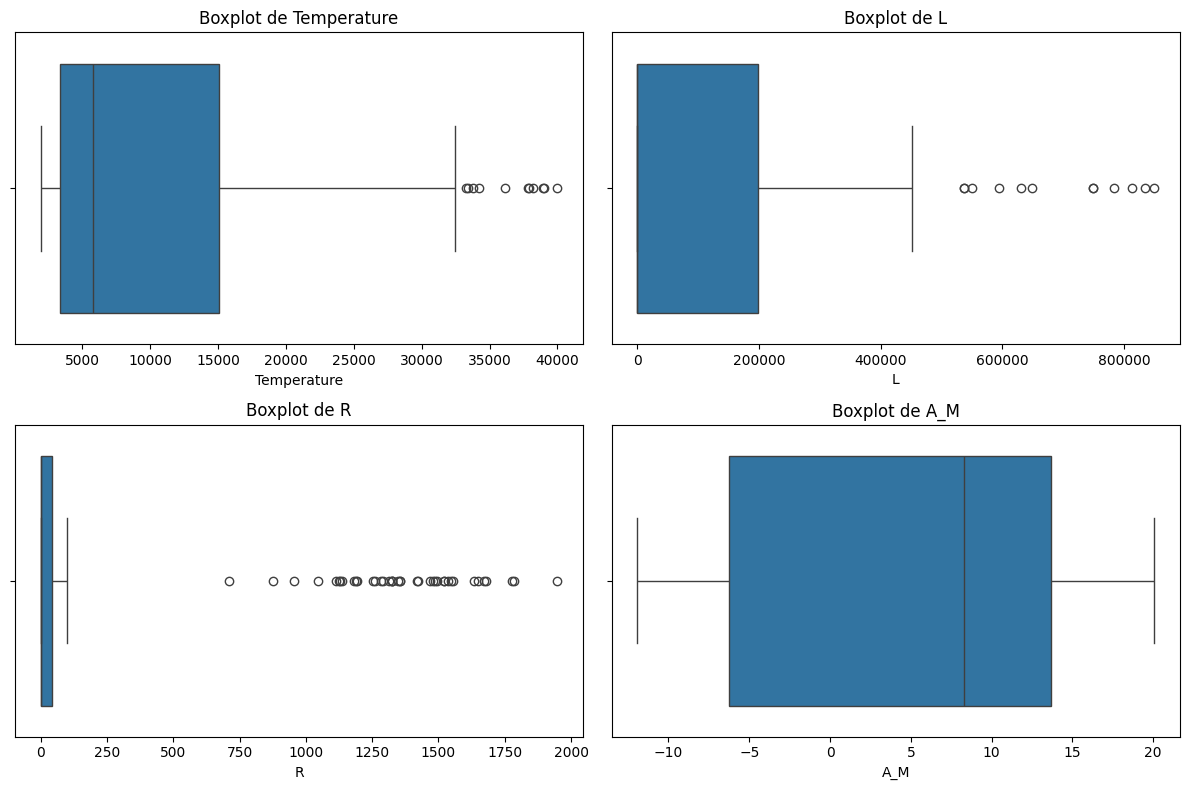

In [10]:
num_cols = ["Temperature", "L", "R", "A_M"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

En este análisis, se puede observar que los boxplots confirman la presencia de valores atípicos. Estos valores son especialmente notorios en `L` y `R`. `Temperature` también presenta algunos valores extremos , aunque de forma menos pronunciada. Por su parte, `A_M` muestra una distribución más equilibrada y sin outliers tan marcados. Esto indica que existen variables presentan una gran dispersión. Esto se deberá tener en cuenta en el preprocesado y en la interpretación de los resultados del clustering.

## 3.6 Valores presentes en las variables categóricas

Ahora se pasará a analizar las variables categóricas del dataset. El objetivo es **identificar los valores presentes** en cada una de ellas y comprobar si existen inconsistencias en su representación. Esto es esencial para la práctica, ya que estas variables deberán transformarse posteriormente mediante **codificación ordinal** antes de aplicar PCA.

In [12]:
# Selección de columnas categóricas
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()

print("Variables categóricas del dataset")
print(cat_cols)

for col in cat_cols:
    print(f"\nColumna: {col}")
    print(f"Número de categorías: {df[col].nunique()}")
    print("Frecuencia de cada categoría:")
    display(df[col].value_counts())

    print("Valores únicos")
    print(sorted(df[col].unique()))

Variables categóricas del dataset
['Color', 'Spectral_Class']

Columna: Color
Número de categorías: 17
Frecuencia de cada categoría:


Color
Red                   112
Blue                   56
Blue-white             26
Blue White             10
yellow-white            8
White                   7
Blue white              4
Yellowish White         3
white                   3
Whitish                 2
Orange                  2
yellowish               2
Pale yellow orange      1
White-Yellow            1
Yellowish               1
Orange-Red              1
Blue-White              1
Name: count, dtype: int64

Valores únicos
['Blue', 'Blue White', 'Blue white', 'Blue-White', 'Blue-white', 'Orange', 'Orange-Red', 'Pale yellow orange', 'Red', 'White', 'White-Yellow', 'Whitish', 'Yellowish', 'Yellowish White', 'white', 'yellow-white', 'yellowish']

Columna: Spectral_Class
Número de categorías: 7
Frecuencia de cada categoría:


Spectral_Class
M    111
B     46
O     40
A     19
F     17
K      6
G      1
Name: count, dtype: int64

Valores únicos
['A', 'B', 'F', 'G', 'K', 'M', 'O']


Este anáisis muestra que `Spectral_Class` tiene una estructura **limpia**, con **7 categorías** bien definidas, lo que hará más dacil su codificación ordinal posterior. Sin embargo, la variable `Color` contiene **17 categorías**, varias de las cuales parecen corresponder a formas distintas de representas los mismos colores, como es el caso con `Blue-white`, `Blue White`, `Blue white`o `Blue-White`, así como con `White` y `white` y otras variables similares.

Esto indica que, antes de aplicar codificación ordinal, es necesario realizar una **limpieza y unificación de etiquetas** en la variabel `Color`, con el fin de evitar qeu diferencias únicamente de escritura generen categorías distintas.

## 4. Preprocesado y reducción de dimensionalidad

Una vez completado el EDA, el siguiente paso consiste en preparar los datos para aplicar clustering. Para ello, primero se normalizan y codifican a forma **ordinal** las variables categóricas (`Color` y `Spectral_Class`). Después, se escalan todas las variables y se aplica **PCA** para proyectar los datos en dos dimensiones.

### 4.1 Limpieza y codificación ordinal de variables categóricas

La variable `Spectral_Class` ya aparece con una notación homogénea, pero `Color` contiene varias inconsistencias de escritura: diferencias entre mayúsculas y minúsculas, guiones y etiquetas equivalentes como `Blue White`, `Blue-white` o `yellow-white`. Por tanto, primero unificamos todas las entradas.

A continuación asignamos códigos ordinales con el criterio de que valores más altos representen estrellas **más calientes y energéticas**. Así, para `Spectral_Class` se sigue la secuencia térmica `M < K < G < F < A < B < O`, y para `Color` para el color utilizamos `red < orange < yellow < white < blue`.

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df_model = df.copy()

df_model['Color_clean'] = (
    df_model['Color']
    .str.lower()
    .str.strip()
    .str.replace('-', ' ', regex=False)
    .str.replace(r'\s+', ' ', regex=True)
)

color_unification = {
    'blue white': 'blue white',
    'blue': 'blue',
    'red': 'red',
    'orange red': 'orange red',
    'orange': 'orange',
    'pale yellow orange': 'pale yellow orange',
    'yellowish': 'yellow',
    'yellowish white': 'yellow white',
    'yellow white': 'yellow white',
    'white yellow': 'yellow white',
    'yellow': 'yellow',
    'white': 'white',
    'whitish': 'white'
}

df_model['Color_clean'] = df_model['Color_clean'].replace(color_unification)

spectral_map = {'M': 0, 'K': 1, 'G': 2, 'F': 3, 'A': 4, 'B': 5, 'O': 6}
color_map = {
    'red': 0,
    'orange red': 1,
    'orange': 2,
    'pale yellow orange': 3,
    'yellow': 4,
    'yellow white': 5,
    'white': 6,
    'blue white': 7,
    'blue': 8
}

unknown_colors = sorted(set(df_model['Color_clean']) - set(color_map))
unknown_spectral = sorted(set(df_model['Spectral_Class']) - set(spectral_map))

if unknown_colors:
    raise ValueError(f'Hay colores sin mapear: {unknown_colors}')
if unknown_spectral:
    raise ValueError(f'Hay clases espectrales sin mapear: {unknown_spectral}')

color_mapping_df = pd.DataFrame({
    'Color normalizado': list(color_map.keys()),
    'Código ordinal': list(color_map.values())
})

spectral_mapping_df = pd.DataFrame({
    'Clase espectral': list(spectral_map.keys()),
    'Código ordinal': list(spectral_map.values())
})

display(pd.DataFrame({
    'Color original': sorted(df['Color'].unique()),
}))

display(
    df_model[['Color', 'Color_clean']]
    .drop_duplicates()
    .sort_values(['Color_clean', 'Color'])
    .reset_index(drop=True)
)

display(color_mapping_df)
display(spectral_mapping_df)

df_model['Color'] = df_model['Color_clean'].map(color_map)
df_model['Spectral_Class'] = df_model['Spectral_Class'].map(spectral_map)
df_model = df_model.drop(columns=['Color_clean'])

display(df_model.head())

ModuleNotFoundError: No module named 'sklearn'

### 4.2 Escalado de variables y PCA

Antes de aplicar PCA, se estandarizan todas las variables para evitar que atributos con magnitudes mucho mayores, como `L` o `R`, dominen el análisis. Después se ajusta PCA sobre los datos escalados y se estudia cuánta varianza explican las componentes principales.

Comprobación rápida del escalado (medias ~ 0 y desviaciones típicas ~ 1):


,Temperature,L,R,A_M,Color,Spectral_Class
media,-0.0,0.0,-0.0,-0.0,0.0,-0.0
desv_tipica,1.0,1.0,1.0,1.0,1.0,1.0


,Componente,Varianza explicada,Varianza acumulada
0,PC1,55.42%,55.42%
1,PC2,29.70%,85.12%
2,PC3,6.38%,91.51%
3,PC4,4.79%,96.30%
4,PC5,3.48%,99.78%
5,PC6,0.22%,100.00%


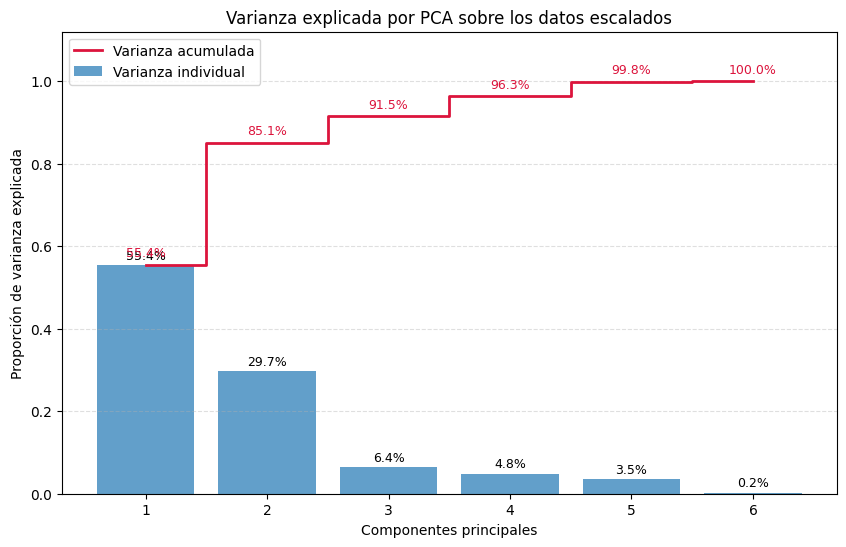

In [ ]:
feature_names = df_model.columns.tolist()
X = df_model[feature_names]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
df_scaled = pd.DataFrame(X_scaled, columns=feature_names)

scaling_check = pd.DataFrame(
    [df_scaled.mean(), df_scaled.std(ddof=0)],
    index=['media', 'desv_tipica']
)

print('Comprobación rápida del escalado (medias ~ 0 y desviaciones típicas ~ 1):')
display(scaling_check.round(6))

pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_df = pd.DataFrame({
    'Componente': [f'PC{i}' for i in range(1, len(explained_variance) + 1)],
    'Varianza explicada': explained_variance,
    'Varianza acumulada': cumulative_variance
})

display(
    variance_df.style.format({
        'Varianza explicada': '{:.2%}',
        'Varianza acumulada': '{:.2%}'
    })
)

plt.figure(figsize=(10, 6))
plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    alpha=0.7,
    label='Varianza individual'
)
plt.step(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    where='mid',
    color='crimson',
    linewidth=2,
    label='Varianza acumulada'
)

for i, (ev, cv) in enumerate(zip(explained_variance, cumulative_variance), start=1):
    plt.text(i, ev + 0.015, f'{ev:.1%}', ha='center', fontsize=9)
    plt.text(i, cv + 0.02, f'{cv:.1%}', ha='center', color='crimson', fontsize=9)

plt.xlabel('Componentes principales')
plt.ylabel('Proporción de varianza explicada')
plt.title('Varianza explicada por PCA sobre los datos escalados')
plt.ylim(0, 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend()
plt.show()

Las dos primeras componentes principales concentran alrededor del **85%** de la varianza total, con una aportación claramente mayor de `PC1` que de `PC2`. Esto justifica trabajar en dos dimensiones en los apartados de clustering, ya que se conserva la mayor parte de la estructura del problema sin renunciar a una visualización clara. Además, con 4 componentes ya se supera aproximadamente el **96%** de varianza acumulada, lo que sugiere que existe redundancia entre algunas variables originales.

Cargas de las variables originales sobre las dos primeras componentes:


,PC1,PC2
Temperature,0.470,-0.214
L,0.368,0.406
R,0.171,0.634
A_M,-0.400,-0.403
Color,0.468,-0.349
Spectral_Class,0.485,-0.319


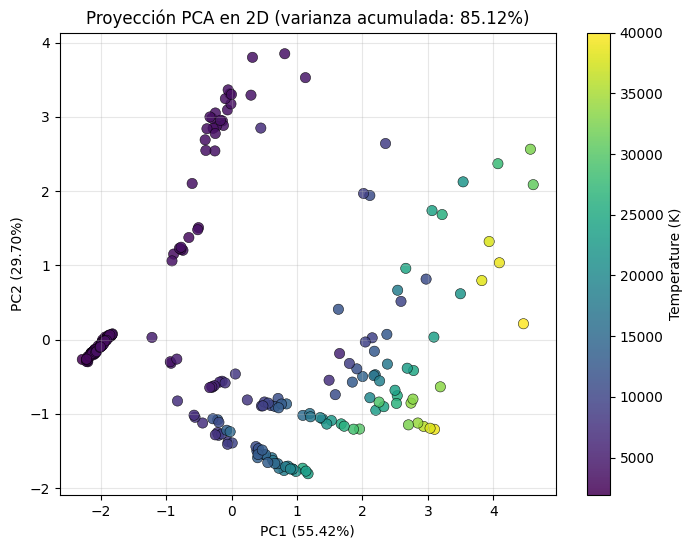

,PC1,PC2
0,-2.076410,-0.141135
1,-2.095980,-0.158994
2,-2.197765,-0.229721
3,-2.109804,-0.155463
4,-2.282131,-0.267054


In [ ]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])

loadings_df = pd.DataFrame(
    pca_2d.components_.T,
    index=feature_names,
    columns=['PC1', 'PC2']
)

print('Cargas de las variables originales sobre las dos primeras componentes:')
display(loadings_df.style.format('{:.3f}'))

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df_pca['PC1'],
    df_pca['PC2'],
    c=df_model['Temperature'],
    cmap='viridis',
    s=55,
    edgecolor='black',
    linewidth=0.4,
    alpha=0.85
)
plt.title(
    f'Proyección PCA en 2D (varianza acumulada: {pca_2d.explained_variance_ratio_.sum():.2%})'
)
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.2%})')
plt.grid(alpha=0.3)
plt.colorbar(scatter, label='Temperature (K)')
plt.show()

display(df_pca.head())

Las cargas del PCA indican que la primera componente principal (`PC1`) recoge sobre todo información relacionada con la temperatura de la estrella, ya que las variables con mayor peso son `Spectral_Class`, `Temperature` y `Color`. Por tanto, esta componente puede interpretarse como un eje que separa estrellas más frías de estrellas más calientes. La segunda componente (`PC2`) está más relacionada con el tamaño y la luminosidad, porque las variables con mayor contribución son `R`, `L` y `A_M`. En consecuencia, la proyección en dos dimensiones resume principalmente un eje térmico y otro asociado al tamaño/brillo estelar. El dataframe `df_pca` contiene esa representación reducida y será la entrada de los algoritmos de clustering.